# Czasy przybycia nowych tranzakcji

Obserwujemy proces $X_t$, gdzie wartości tego procesu oznaczają uporządkowane czasy przybycia tranzakcji. Mamy jednak tylko dostęp do sekund, nie mamy dostępu do mikro ani nanosekund.

Oznacza to, że $X_t$ może równać się $X_{t+1}$, $X_{t+2}$, $X_{t+3}$. Jeśli będziemy mieli $n$ obserwacji o tym samym czasie: $X_t = X_{t+1} = \ldots = X_{t+n-1}$, to wtedy uporządkujemy te czasy jednostajnie.

Na przykład, jeśli $s = X_t = X_{t+1} \neq X_{t+2}$, to wówczas  $n = 2$, $X_t = s + \frac{1}{3}$, a $X_{t+1} = s + \frac{2}{3}$.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

## Wczytanie danych

In [15]:
path = 'data/bitcoin_data.parquet'
data_raw = pq.read_pandas(path)
data_raw

pyarrow.Table
tx_id: string
conf_block_hash: string
found_at: timestamp[ns]
mined_at: timestamp[ns]
fee_rate_original: double
waittime: int64
weight_original: int64
size_original: int64
min_respend_blocks: int64
child_txid: string
rbf_fee_total: double
mempool_tx_count: double
mempool_size: double
total_output_amount: int64
absolute_fee_original: int64
weight: double
size: double
fee_rate: double
absolute_fee: double
vsize: double
has_corrected_weight: bool
label: string
n_in: int64
n_out: int64
has_op_return: int64
has_inscription: int64
block_height: int64
block_time: int64
block_tx_count: int64
block_total_weight: int64
block_median_feerate: double
block_p10_feerate: double
block_p90_feerate: double
time_since_last_block: double
gap_to_prev_block: double
ema_feerate_3block: double
is_cpfp_package: int64
found_at_ts: int64
epoch_id: int64
fee_rate_percentile: double
impatience: double
cumulative_weight: double
blockspace_utilization: double
log_weight: double
log_waittime: double
log

In [16]:
data = data_raw.to_pandas()
ilosc_danych = len(data)
ilosc_danych

11110277

In [17]:
czasy = data['found_at']
czasy = czasy.sort_values().reset_index(drop=True)
czasy

0          2025-08-03 06:27:44
1          2025-08-03 06:27:44
2          2025-08-03 06:27:44
3          2025-08-03 06:27:44
4          2025-08-03 06:27:45
                   ...        
11110272   2025-10-09 20:44:16
11110273   2025-10-09 20:44:17
11110274   2025-10-09 20:44:19
11110275   2025-10-09 20:44:19
11110276   2025-10-09 20:44:20
Name: found_at, Length: 11110277, dtype: datetime64[ns]

Znalezione w internecie, zwróci ile jest nanosekund i mikrosekund

# Wstępna analiza

In [18]:
ile_obserwacji_w_sekundzie = czasy.value_counts()
ile_obserwacji_w_sekundzie

found_at
2025-08-11 05:49:09    321
2025-08-11 05:41:58    300
2025-08-14 21:41:17    290
2025-08-07 00:19:06    288
2025-08-11 05:40:55    285
                      ... 
2025-10-09 20:43:58      1
2025-10-09 20:44:14      1
2025-10-09 20:44:16      1
2025-10-09 20:44:17      1
2025-10-09 20:44:20      1
Name: count, Length: 2211272, dtype: int64

In [19]:
czasy

0          2025-08-03 06:27:44
1          2025-08-03 06:27:44
2          2025-08-03 06:27:44
3          2025-08-03 06:27:44
4          2025-08-03 06:27:45
                   ...        
11110272   2025-10-09 20:44:16
11110273   2025-10-09 20:44:17
11110274   2025-10-09 20:44:19
11110275   2025-10-09 20:44:19
11110276   2025-10-09 20:44:20
Name: found_at, Length: 11110277, dtype: datetime64[ns]

In [20]:
roznice = czasy.diff()
roznice

0                      NaT
1          0 days 00:00:00
2          0 days 00:00:00
3          0 days 00:00:00
4          0 days 00:00:01
                 ...      
11110272   0 days 00:00:01
11110273   0 days 00:00:01
11110274   0 days 00:00:02
11110275   0 days 00:00:00
11110276   0 days 00:00:01
Name: found_at, Length: 11110277, dtype: timedelta64[ns]

In [21]:
roznice.value_counts()

found_at
0 days 00:00:00    8899005
0 days 00:00:01    1773749
0 days 00:00:02     283831
0 days 00:00:03      55579
0 days 00:00:04      17420
                    ...   
0 days 00:04:36          1
0 days 00:03:42          1
0 days 00:02:16          1
0 days 00:03:27          1
0 days 00:10:07          1
Name: count, Length: 196, dtype: int64

# 7.8kk z 11kk danych ma wartosc 0, a prawie 2kk 1.

## Pomysł
Wczytam wszyskie różnice, tam gdzie czasy będą te same wezmę $\frac{1}{n}$, gdzie n to liczba wszystkich obserwacji w danej sekundzie z uwzględnieniem przesunięcia.

Jeśli w danej sekundzie było $n$ danych, to zakładam, że pierwsza przyszła w $\frac{1}{2n}$ części sekundy, a ostatnia w $1 - \frac{1}{2n}$ częsci sekundy

In [22]:
czasy_oczekiwania = []

for i in range(1, ilosc_danych):
    czas_obecny = czasy[i]
    czas_poprzedni = czasy[i-1]
    if czas_obecny == czas_poprzedni:
        # Jesli czasy sa takie same, to biore 1/n
        czas_oczekiwania = 1 / ile_obserwacji_w_sekundzie[czas_obecny]
    else:
        # W przeciwynym wypadku obliczam roznice ale z poprawka, ze tranzakcje nie pojawily sie na poczatku sekund
        czas_oczekiwania = (czas_obecny - czas_poprzedni).total_seconds()
        # pierwszy w 1 - 1/(2*n) czesci sekundy a drugi w 1/(2*m), gdzie n i m to licznosci
        czas_oczekiwania += - 1 + 1/(2*ile_obserwacji_w_sekundzie[czas_poprzedni]) + 1/(2*ile_obserwacji_w_sekundzie[czas_obecny])
    if czas_oczekiwania < 0:
        print(i, czas_obecny, czas_poprzedni, czas_oczekiwania)
        int(input('wpisz cos'))

    czasy_oczekiwania.append(czas_oczekiwania)

In [58]:
czasy_oczekiwania

[np.float64(0.25),
 np.float64(0.25),
 np.float64(0.25),
 np.float64(0.375),
 np.float64(0.5),
 np.float64(0.41666666666666663),
 np.float64(0.3333333333333333),
 np.float64(0.3333333333333333),
 np.float64(0.2666666666666666),
 np.float64(0.2),
 np.float64(0.2),
 np.float64(0.2),
 np.float64(0.2),
 np.float64(0.6),
 np.float64(0.6666666666666666),
 np.float64(0.3333333333333333),
 np.float64(0.3333333333333333),
 np.float64(0.29166666666666663),
 np.float64(0.25),
 np.float64(0.25),
 np.float64(0.25),
 np.float64(0.375),
 np.float64(0.5),
 np.float64(0.75),
 np.float64(0.6666666666666666),
 np.float64(0.3333333333333333),
 np.float64(0.3333333333333333),
 np.float64(0.41666666666666663),
 np.float64(0.5),
 np.float64(0.41666666666666663),
 np.float64(0.3333333333333333),
 np.float64(0.3333333333333333),
 np.float64(0.41666666666666663),
 np.float64(0.5),
 np.float64(0.75),
 np.float64(1.0),
 np.float64(0.75),
 np.float64(0.5),
 np.float64(0.35),
 np.float64(0.2),
 np.float64(0.2),
 np

### Statystyki

In [24]:
np.mean(czasy_oczekiwania)

np.float64(0.5256571821438097)

In [25]:
np.var(czasy_oczekiwania)

np.float64(199857.55098275217)

In [26]:
np.max(czasy_oczekiwania)

np.float64(1197519.0)

In [27]:
np.min(czasy_oczekiwania)

np.float64(0.003115264797507788)

In [28]:
np.quantile(czasy_oczekiwania, 0.5)

np.float64(0.14285714285714285)

In [29]:
np.quantile(czasy_oczekiwania, 0.25)

np.float64(0.05)

In [30]:
np.quantile(czasy_oczekiwania, 0.75)

np.float64(0.29166666666666663)

In [31]:
np.quantile(czasy_oczekiwania, 0.95)

np.float64(0.75)

In [32]:
np.quantile(czasy_oczekiwania, 0.99)

np.float64(2.5833333333333335)

In [33]:
np.quantile(czasy_oczekiwania, 0.999)

np.float64(19.506849315068493)

## Usuwam 0,1% najwyższych wartości

In [34]:
kwantyl999 = np.quantile(czasy_oczekiwania, 0.999)
czasy_oczekiwania_q_999 = [i for i in czasy_oczekiwania if i < kwantyl999]

In [35]:
np.mean(czasy_oczekiwania_q_999)

np.float64(0.2972861390243581)

In [36]:
np.var(czasy_oczekiwania_q_999)

np.float64(0.7529873774284748)

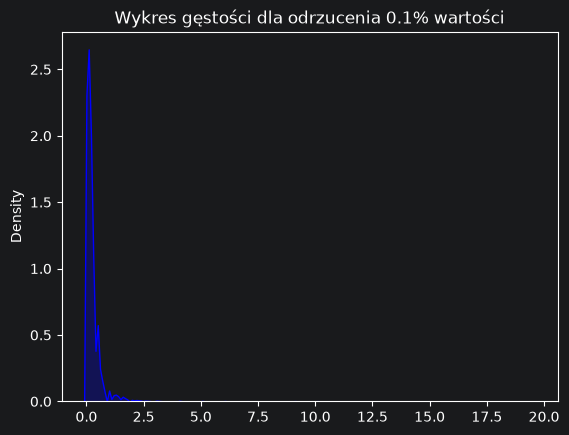

In [37]:
import seaborn as sns

sns.kdeplot(czasy_oczekiwania_q_999, fill=True, color="blue")

plt.title("Wykres gęstości dla odrzucenia 0.1% wartości")

plt.show()

## Usuwam 1% najwyższych wartości

In [38]:
kwantyl99 = np.quantile(czasy_oczekiwania, 0.99)
czasy_oczekiwania_q_99 = [i for i in czasy_oczekiwania if i < kwantyl99]

In [39]:
np.mean(czasy_oczekiwania_q_99)

np.float64(0.23171798009639755)

In [40]:
np.var(czasy_oczekiwania_q_99)

np.float64(0.08797687879826624)

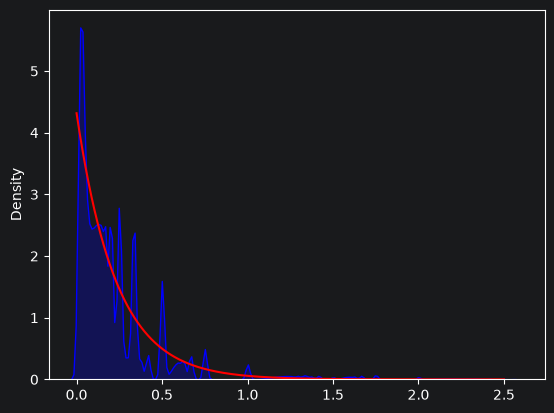

In [41]:
sns.kdeplot(czasy_oczekiwania_q_99, fill=True, color="blue")



lam = 1 / np.mean(czasy_oczekiwania_q_99)
x = np.linspace(0, 2.5, 1000)
f = lam * np.exp(-lam * x)
plt.plot(x, f, 'r')

plt.show()

# Testy na rozkład wykładniczy

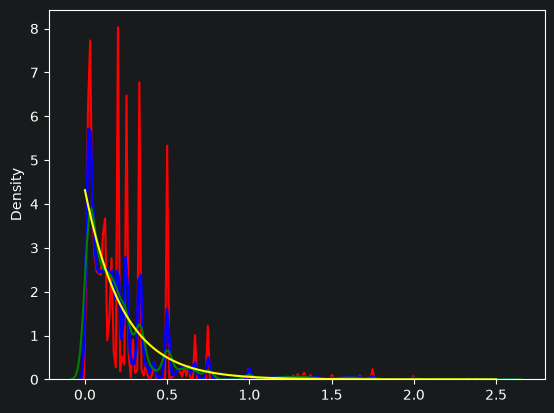

In [42]:
sns.kdeplot(czasy_oczekiwania_q_99, bw_adjust=0.3, label="Małe wygładzenie (poszarpany)", color="red")
sns.kdeplot(czasy_oczekiwania_q_99, bw_adjust=1.0, label="Domyślne wygładzenie", color="blue", linewidth=2)
sns.kdeplot(czasy_oczekiwania_q_99, bw_adjust=2.5, label="Duże wygładzenie (bardzo gładki)", color="green")


plt.plot(x, f, 'yellow')

plt.show()



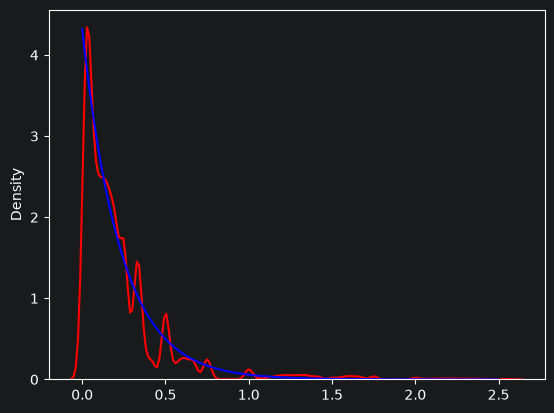

In [43]:
sns.kdeplot(czasy_oczekiwania_q_99, bw_adjust=2, label="2", color="red")


plt.plot(x, f, 'blue')

plt.show()


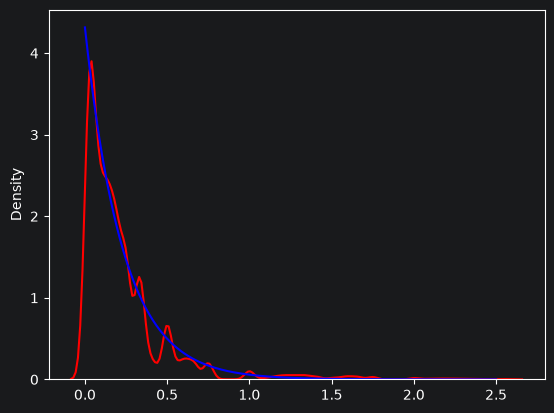

In [44]:
sns.kdeplot(czasy_oczekiwania_q_99, bw_adjust=2.5, label="2.5", color="red")


plt.plot(x, f, 'blue')

plt.show()


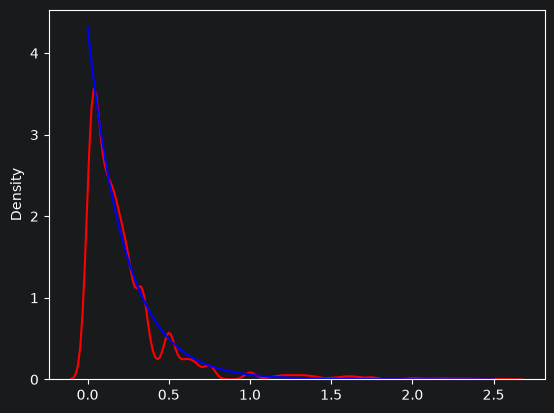

In [45]:
sns.kdeplot(czasy_oczekiwania_q_99, bw_adjust=3, label="3", color="red")


plt.plot(x, f, 'blue')

plt.show()

# Analiza poprzez ilosc pojawienia sie zjawiska w danej sekundzie

In [46]:
len(ile_obserwacji_w_sekundzie)

2211272

In [47]:
mask = ile_obserwacji_w_sekundzie == 1
mask

found_at
2025-08-11 05:49:09    False
2025-08-11 05:41:58    False
2025-08-14 21:41:17    False
2025-08-07 00:19:06    False
2025-08-11 05:40:55    False
                       ...  
2025-10-09 20:43:58     True
2025-10-09 20:44:14     True
2025-10-09 20:44:16     True
2025-10-09 20:44:17     True
2025-10-09 20:44:20     True
Name: count, Length: 2211272, dtype: bool

In [48]:
sum(mask)

435621

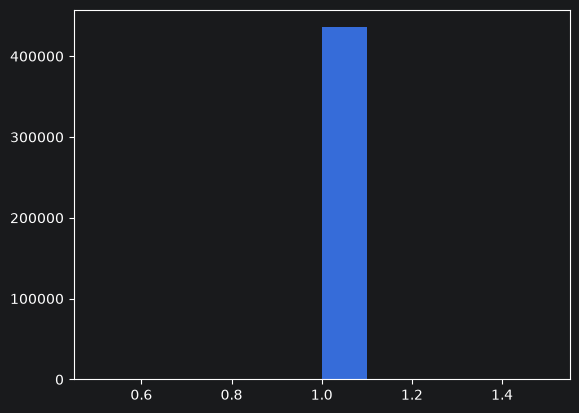

In [49]:
plt.hist(ile_obserwacji_w_sekundzie[mask])
plt.show()

In [50]:
mask = ile_obserwacji_w_sekundzie == 2
sum(mask)

432064

In [51]:
total = 0
l = []
for i in range(1, 40):
    mask = ile_obserwacji_w_sekundzie == i
    s = sum(mask)
    print(f"Jest {s} chwil w których przybyło {i} tranzakcji")
    total += s
    l.append(s)

print(f"Jest {total} chwil w których przybyło poniżej 40 tranzakcji")

Jest 435621 chwil w których przybyło 1 tranzakcji
Jest 432064 chwil w których przybyło 2 tranzakcji
Jest 361747 chwil w których przybyło 3 tranzakcji
Jest 271639 chwil w których przybyło 4 tranzakcji
Jest 190723 chwil w których przybyło 5 tranzakcji
Jest 130119 chwil w których przybyło 6 tranzakcji
Jest 87533 chwil w których przybyło 7 tranzakcji
Jest 59245 chwil w których przybyło 8 tranzakcji
Jest 40811 chwil w których przybyło 9 tranzakcji
Jest 29078 chwil w których przybyło 10 tranzakcji
Jest 21307 chwil w których przybyło 11 tranzakcji
Jest 16202 chwil w których przybyło 12 tranzakcji
Jest 12969 chwil w których przybyło 13 tranzakcji
Jest 10326 chwil w których przybyło 14 tranzakcji
Jest 8528 chwil w których przybyło 15 tranzakcji
Jest 7552 chwil w których przybyło 16 tranzakcji
Jest 6403 chwil w których przybyło 17 tranzakcji
Jest 5733 chwil w których przybyło 18 tranzakcji
Jest 5168 chwil w których przybyło 19 tranzakcji
Jest 4675 chwil w których przybyło 20 tranzakcji
Jest 4285

In [52]:
np.mean(ile_obserwacji_w_sekundzie)

np.float64(5.0243827986787695)

In [53]:
np.var(ile_obserwacji_w_sekundzie)

np.float64(58.93436734722984)

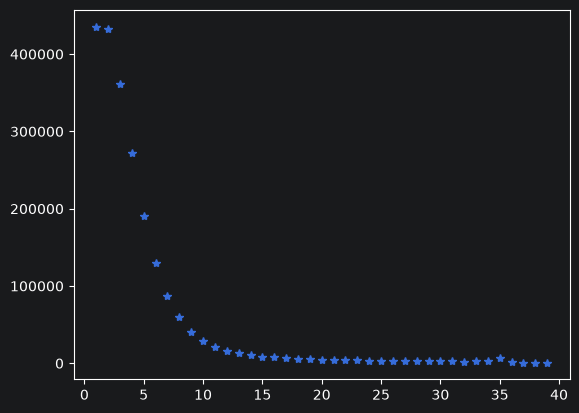

In [54]:
plt.plot([i for i in range(1,40)], l, "*")
plt.show()

Analiza ze względu na możliwość dawania wielu tranzakcji na raz; możliwe, że kilku ludzi daje naraz "paczki", co zaburza proces - sprawdzic po adresach; analiza danych adresowych, opisać proces Xt,

In [55]:
data

,tx_id,conf_block_hash,found_at,mined_at,fee_rate_original,waittime,weight_original,size_original,min_respend_blocks,child_txid,...,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,log_n_in,log_n_out,is_consolidation,is_coinjoin,is_datacarrying
0,e0062963708a3f49c89b6cb252a57808188a05752cf7db...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:27,1.0,2490,452,113,11,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.098612,0,0,0
1,766ade3892c0c796756c135f80adaea15545a89d1e8dfd...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:26,1.0,2489,548,137,3499,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.098612,0,0,0
2,4e491c09d81817d21afb647820c374143a30d7334b635e...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:26,1.0,2489,576,144,3,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.386294,0,0,0
3,2a1f8638e69d39bb57c78f6e40558c61eccf857e1ddaea...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:41:14,2025-09-09 22:22:26,1.0,2472,328,82,35,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,0.693147,0,0,0
4,ce72aa8d04042d3aa0ebc9588529adfcecedd0fbda5fd2...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:41:14,2025-09-09 22:22:25,1.0,2471,11808,2952,3,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,4.276666,0.693147,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11110272,402fc499134d0f9a61df1d3f64dc973b7266997d454c42...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:38,3.0,29,732,183,35,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,0.693147,1.386294,0,0,1
11110273,05e746c504ef75534a0b729e72cc501a85ff90da45c7df...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:39,3.0,30,616,154,655,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,1.098612,1.098612,0,0,0
11110274,b3238a3931e970786a3d74701193f2adffa1b4e67f8a53...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:38,3.0,29,820,205,10,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,1.609438,0.693147,1,0,0
11110275,131c10ccd05131c463240ad48c1af79486d5a362d3bd84...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:41,1.0,32,884,221,10,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,0.693147,1.609438,0,0,1


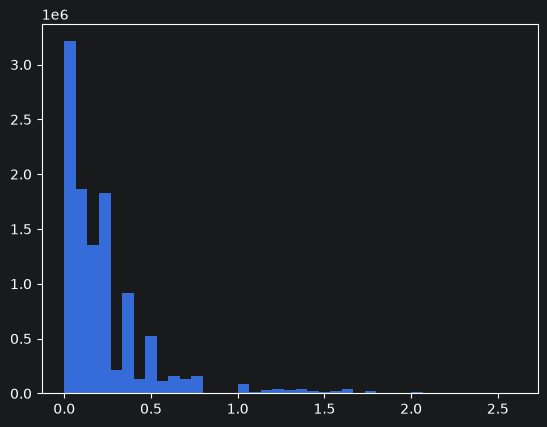

In [59]:
plt.hist(czasy_oczekiwania_q_99, bins = [i/15 for i in range(0, 40)])
plt.show()


To bez sensu, jest luka pomiędzy 0.8 a 1 ze względu na metodologie

# Analiza czasów przybycia

In [61]:
data

,tx_id,conf_block_hash,found_at,mined_at,fee_rate_original,waittime,weight_original,size_original,min_respend_blocks,child_txid,...,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,log_n_in,log_n_out,is_consolidation,is_coinjoin,is_datacarrying
0,e0062963708a3f49c89b6cb252a57808188a05752cf7db...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:27,1.0,2490,452,113,11,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.098612,0,0,0
1,766ade3892c0c796756c135f80adaea15545a89d1e8dfd...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:26,1.0,2489,548,137,3499,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.098612,0,0,0
2,4e491c09d81817d21afb647820c374143a30d7334b635e...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:26,1.0,2489,576,144,3,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.386294,0,0,0
3,2a1f8638e69d39bb57c78f6e40558c61eccf857e1ddaea...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:41:14,2025-09-09 22:22:26,1.0,2472,328,82,35,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,0.693147,0,0,0
4,ce72aa8d04042d3aa0ebc9588529adfcecedd0fbda5fd2...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:41:14,2025-09-09 22:22:25,1.0,2471,11808,2952,3,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,4.276666,0.693147,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11110272,402fc499134d0f9a61df1d3f64dc973b7266997d454c42...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:38,3.0,29,732,183,35,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,0.693147,1.386294,0,0,1
11110273,05e746c504ef75534a0b729e72cc501a85ff90da45c7df...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:39,3.0,30,616,154,655,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,1.098612,1.098612,0,0,0
11110274,b3238a3931e970786a3d74701193f2adffa1b4e67f8a53...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:38,3.0,29,820,205,10,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,1.609438,0.693147,1,0,0
11110275,131c10ccd05131c463240ad48c1af79486d5a362d3bd84...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:41,1.0,32,884,221,10,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,0.693147,1.609438,0,0,1


In [69]:
czasy_wykopania = data['mined_at'] - data["found_at"]
czasy_wykopania

0          0 days 00:41:30
1          0 days 00:41:29
2          0 days 00:41:29
3          0 days 00:41:12
4          0 days 00:41:11
                 ...      
11110272   0 days 00:00:29
11110273   0 days 00:00:30
11110274   0 days 00:00:29
11110275   0 days 00:00:32
11110276   0 days 00:00:32
Length: 11110277, dtype: timedelta64[ns]

In [70]:
czasy_wykopania = czasy_wykopania.apply(lambda x: x.total_seconds())
czasy_wykopania

0           2490.0
1           2489.0
2           2489.0
3           2472.0
4           2471.0
             ...  
11110272      29.0
11110273      30.0
11110274      29.0
11110275      32.0
11110276      32.0
Length: 11110277, dtype: float64

In [72]:
np.min(czasy_wykopania)

np.float64(0.0)

In [73]:
np.max(czasy_wykopania)

np.float64(1172305.0)

In [74]:
np.mean(czasy_wykopania)

np.float64(1432.085830983332)

In [75]:
np.var(czasy_wykopania)

np.float64(103720731.16828401)

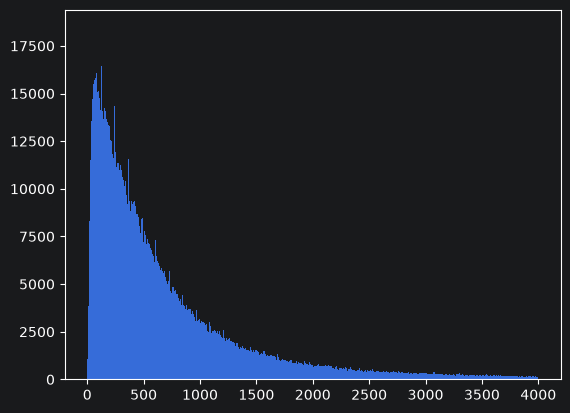

In [80]:
plt.hist(czasy_wykopania, bins = [i for i in range(0, 4000)])
plt.show()

In [87]:
q99 =np.quantile(czasy_wykopania, 0.99)
q99

np.float64(16398.0)

In [86]:
q995 = np.quantile(czasy_wykopania, 0.995)
q995

np.float64(31704.0)

In [88]:
czasy_wykopania99 = czasy_wykopania[czasy_wykopania < q99]
czasy_wykopania99

0           2490.0
1           2489.0
2           2489.0
3           2472.0
4           2471.0
             ...  
11110272      29.0
11110273      30.0
11110274      29.0
11110275      32.0
11110276      32.0
Length: 10999170, dtype: float64

In [ ]:
sns.kdeplot(czasy_wykopania99, bw_adjust=1, label="1", color="red")


plt.show()